## 05 · Clima y precio: ¿existe una relación cuantificable?

**Fase 3 · limpieza y cruzamiento.** Última pieza del rompecabezas: ¿el clima tiene
algo que ver con la evolución de los precios? Se calculan las **anomalías climáticas
anuales** frente a la normal histórica y se correlacionan con la variación del precio
en el cuadro maestro.

**Especificación exacta de los datos que se usan aquí.**

| Insumo | Ruta | Volumen | Granularidad | Periodo |
|---|---|---|---|---|
| Lecturas meteorológicas (F3) | `data/crudo/MET_Office_Weather_Data.csv` | 37.049 registros | estación × mes | 1931-2020 |
| Precios y salario (F4) | `data/crudo/Average_UK_houseprices_and_salary.csv` | 46 años | año nacional | 1975-2020 |
| Brecha salarial por edad (F4b) | `data/crudo/Income_by_age_and_gender.csv` | mediana por edad | grupo de edad × género | 2021 |
| Transacciones (F1) | agregadas a región-año | 11.369.413 → 60 | región × año | 2015-2020 |
| Cuadro maestro resultante | `data/integrado/maestro_joven_uk.parquet` | **60 filas × 16 columnas** | región × año | 2015-2020 |

**Unidades.** La temperatura se mide en **grados Celsius**, la lluvia en **mm**, el
sol en **horas** y las heladas en **días**; las cinco anomalías son diferencias
respecto a la normal. La variación del precio (`precio_var_pct`) es un **porcentaje
anual** y el precio mediano va en **GBP**.

**La decisión estadística que gobierna todo este cuaderno.** La pregunta "¿el clima
explica el precio?" tiene una trampa: el clima de una región está confundido con todo
lo demás que la define (salario, oferta, densidad). Por eso la variable de respuesta
**no es el nivel del precio** sino su **variación porcentual anual**, que elimina el
efecto de nivel regional: una constante regional alta desaparece al diferenciar año a
año. Lo que queda es si el *desvío climático del año* se asocia con el *desvío del
crecimiento del precio* del mismo año. Es una asociación, no una causalidad (véase el
punto 5).

## 1. Raíz del proyecto y dependencias del pipeline

Los seis módulos del pipeline se importan aquí: `cargar` (lectura defensiva de cada
fuente), `limpiar` (duplicados, categorías, nulos y atípicos), `transformaciones`
(agregados anuales, anomalías y salario joven), `cruces` (el cuadro maestro),
`indicadores` (correlaciones) y `graficos` (figuras del pipeline). El cuaderno no
recalcula nada a mano: llama a las mismas funciones que usa `main_proyecto.py`, de
modo que el resultado del cuaderno y el del script terminal son idénticos por
construcción.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Se sube en la carpeta hasta encontrar la raiz del proyecto (la que tiene db/ y data/)
# y se anade script/ al path para poder importar los modulos del pipeline.
PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) \
        and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent

sys.path.insert(0, str(PROYECTO / "script"))

if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        f"No se encuentra la carpeta script/ en {PROYECTO}. "
        "Abri este cuaderno desde la raiz del proyecto.")

from proyecto import config
from proyecto import (cargar, limpiar, diagnostico, transformaciones, cruces,
                      indicadores, validacion, graficos)


def presentar(fig):
    display(fig)


print("raiz del proyecto:", PROYECTO.name)
print("fuentes en data/crudo:",
      [p.name for p in config.DATA_CRUDO.glob("*.csv")])

raiz del proyecto: mineria
fuentes en data/crudo: ['Average_UK_houseprices_and_salary.csv', 'Income_by_age_and_gender.csv', 'MET_Office_Weather_Data.csv', 'UK_Mortgage_Rate.csv']


## 2. De lecturas mensuales a anomalías anuales

### La fórmula de la anomalía climática

Una estación es "más lluviosa" o "más cálida" cuando se aleja de **su propia normal**,
no de la de otra estación. Por eso la anomalía es una **diferencia respecto a la media
histórica de esa misma estación**:

    anomalía(año, estación, variable) = valor(año, estación, variable)
                                       − normal(1931-2020, estación, variable)

donde

    normal(1931-2020, estación, variable)
        = MEDIA de los valores anuales de 1931 a 2020 en esa estación

Esta es la **anomalía simple** (diferencia respecto a la normal), **no** una
anomalía estandarizada o z-score. La diferencia importa y conviene entender por qué:
la anomalía simple conserva las **unidades originales** (mm de lluvia, °C, horas de
sol, días de helada), de modo que "lluvia +12 mm" se lee directamente; un z-score
daría "1,4 desviaciones estándar", que depende de la variabilidad de cada variable y
no es comparable entre la lluvia y la temperatura. Como aquí se van a **sumar y comparar
cinco variables distintas**, mantener las unidades físicas es más legible que
normalizar.

La normal de referencia es **1931-2020**, el periodo estándar de 30 años recomendado
meteorológicamente (OMM): promedia lo suficiente para que un año atípico no la mueva,
y coincide con la cobertura completa de la fuente F3.

### Las tres etapas de la agregación

1. **Mensual → anual** por estación: se promedian los 12 meses (los días de helada se
   **suman**, porque son un conteo de días, no una magnitud promediable).
2. **Anual → anomalía**: se resta la normal 1931-2020 de cada estación (fórmula arriba).
3. **Anomalía de estación → anomalía regional**: se promedian las estaciones de cada
   región.

**Por qué este paso promedia y no suma.** La anomalía es una *magnitud desviada*, no un
total: sumarla entre estaciones produciría un número que depende de cuántas estaciones
tenga la región, no de lo anómalo que fue el año. El promedio da una magnitud
interpretable (los +4,2 mm que promedió England en 2018), mientras que la suma solo
serviría como índice de cobertura. **Por qué el promedio de estaciones y no de regiones**:
estaciones contiguas y con microclimas muy próximos son las que comparten un régimen
de lluvia; resumir por estación y luego promediar preserva esa estructura regional que
se quiere medir, en lugar de diluir 36 estaciones en un único valor nacional sin
sentido espacial.

**Alcance geográfico.** Solo las estaciones de Inglaterra y Gales tienen región ONS
asignada, porque F1 (transacciones) no cubre Escocia ni Irlanda del Norte; el total
nacional sí computa las 36 estaciones. Es una limitación deliberada y documentada del
cruce, no un descuido.

In [2]:
c = cargar.cargar_clima()
c_limpio, _ = limpiar.limpiar_clima(c)
anual = transformaciones.clima_anual(c_limpio)
anom_nac, anom_reg = transformaciones.anomalias_climaticas(anual)

print(f"F3 bruto: {c.shape[0]} registros x {c.shape[1]} columnas")
print(f"anual por estacion: {anual.shape[0]} estacion-anos "
      f"({anual['estacion'].nunique()} estaciones)")
print(f"anomalia nacional: {anom_nac.shape[0]} anos x {anom_nac.shape[1] - 1} variables")
print(f"anomalia regional: {anom_reg.shape[0]} region-anos "
      f"({anom_reg['region'].nunique()} regiones)")
display(anom_nac)
print("estaciones por region en el cruce:")
display(pd.Series(config.ESTACION_REGION).value_counts().to_frame("estaciones"))

F3 bruto: 37049 registros x 8 columnas
anual por estacion: 3112 estacion-anos (36 estaciones)
anomalia nacional: 168 anos x 5 variables
anomalia regional: 1027 region-anos (10 regiones)


,anio,tmax_anom,tmin_anom,lluvia_anom,sol_anom,af_anom
0,1853.0,-1.125021,-1.082391,-6.416863,NaN,-4.395833
1,1854.0,0.133312,-0.899057,-8.141863,NaN,-15.895833
2,1855.0,-1.326752,-1.313539,-6.423540,NaN,12.322869
3,1856.0,-0.385085,-0.476039,-5.009399,NaN,-4.677131
4,1857.0,0.606581,0.344795,-1.026065,NaN,-9.677131
...,...,...,...,...,...,...
163,2016.0,0.715796,0.611864,-0.174387,-5.663470,-6.193313
164,2017.0,0.946469,0.947571,-1.140674,-6.385026,-8.344828
165,2018.0,1.029171,0.662318,-1.441053,6.420573,-4.526646
166,2019.0,1.009686,0.777415,8.139334,-2.026566,-10.738767


estaciones por region en el cruce:


,estaciones
Wales,4
South West,4
South East,4
Yorkshire and The Humber,3
East of England,2
North West,2
West Midlands,2
North East,1
London,1
East Midlands,1


## 3. Lluvia nacional en la ventana de estudio

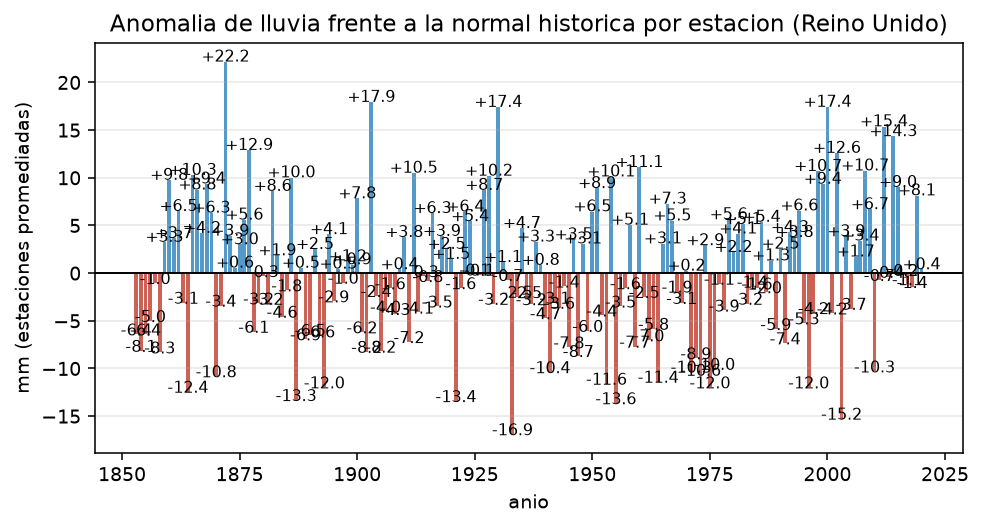

In [3]:
presentar(graficos.fig_anomalia_lluvia(anom_nac))

## 4. Cruzar clima con precios (el maestro)

In [4]:
t = cargar.cargar_precios_limpios()
precios_region = transformaciones.agregado_precios_region(t)
st = transformaciones.serie_salario_joven(cargar.cargar_precios_salario(),
          transformaciones.salario_joven(cargar.cargar_ingreso_edad(),
                                            cargar.cargar_precios_salario())[1])
maestro = cruces.cruce_maestro(precios_region, st, anom_reg)
display(maestro[['anio', 'region', 'precio_mediana', 'precio_var_pct', 'lluvia_anom', 'tmax_anom', 'af_anom']])

,anio,region,precio_mediana,precio_var_pct,lluvia_anom,tmax_anom,af_anom
0,2015,East Midlands,157500.0,NaN,-6.180180,1.000338,-18.459459
1,2016,East Midlands,165000.0,4.761905,3.936486,0.725338,-12.459459
2,2017,East Midlands,178000.0,7.878788,-1.830180,0.942005,-14.459459
3,2018,East Midlands,185500.0,4.213483,-0.996847,1.267005,-8.459459
4,2019,East Midlands,190000.0,2.425876,16.253153,1.083671,-21.459459
5,2020,East Midlands,202500.0,6.578947,-11.946847,0.650338,-34.459459
6,2015,East of England,235000.0,NaN,-5.391098,0.885883,-17.955113
7,2016,East of England,255000.0,8.510638,-4.332765,0.677550,-12.455113
8,2017,East of England,275000.0,7.843137,4.550568,0.685883,-15.955113
9,2018,East of England,280000.0,1.818182,-4.399432,1.085883,-15.455113


## 5. Correlaciones de Pearson entre clima y precio

### La medida y su fórmula

Se aplica el **coeficiente de correlación de Pearson**:

    r = Σ(xᵢ − x̄)(yᵢ − ȳ) / ((n − 1) · sₓ · sᵧ)

que toma valores en **[−1, +1]**: el signo da la **dirección** (suben juntos o uno
sube cuando el otro baja) y el módulo da la **fuerza de la asociación lineal**.

**Guía de interpretación del módulo** (práctica, no dogma: depende del dominio):

| \|r\| | Lectura |
|---|---|
| 0 – 0,1 | Sin relación lineal |
| 0,1 – 0,3 | Débil |
| 0,3 – 0,5 | Moderada |
| 0,5 – 0,7 | Fuerte |
| > 0,7 | Muy fuerte |

**Por qué Pearson y no Spearman.** Se elige Pearson porque el objetivo es medir
asociación **lineal**, y la relación entre una anomalía meteorológica y una variación
de precio se espera lineal (más lluvia ese año → menos suba ese año). La **correlación
de rangos de Spearman** mediría asociación **monótona** (cualquier Relation que
suba o baje de forma consistente, aunque no recta) y se elegiría si los datos
presentaran relaciones curvas. Con n = 50 pares y sin curvatura visible en la
dispersión, Pearson es la medida adequada; además es la que hace comparables los
valores con la guía de umbrales anterior.

**La advertencia que no se puede omitir.** Una correlación de **−0,39 no significa
que la lluvia cause una caída del precio.** La variable de respuesta es la variación
anual dentro de cada región, y esa variación está determinada por un conjunto de
factores simultáneos (tipos de interés, oferta de vivienda, migración, política
local). El clima es **una** variable más. Para sostener una afirmación causal haría
falta un diseño que aislara el efecto climático (comparar años con anomalías
opuestas en la misma región manteniendo constantes las demás condiciones), que está
fuera del alcance de este cruce descriptivo.

In [5]:
corr = indicadores.correlacion_clima_precio(maestro)
display(corr.round(3))

print("lectura de la magnitud |r| (guia practica):")
for _, fila in corr.iterrows():
    r = abs(fila["pearson"])
    etiqueta = ("sin relacion lineal" if r < 0.1 else
                "debil" if r < 0.3 else
                "moderada" if r < 0.5 else
                "fuerte" if r < 0.7 else "muy fuerte")
    print(f"  {fila['clima']:<12} r = {fila['pearson']:+.3f}  -> {etiqueta}"
          f"  (n = {int(fila['n'])} pares)")

print()
print("signo negativo = a mayor anomalia (mas lluvia o mas calor), menor suba del precio")
print("todos los |r| < 0.5: ningun factor climatico explica por si solo el precio")

,clima,pearson,n
0,lluvia_anom,-0.241,50
1,tmax_anom,-0.388,50
2,tmin_anom,-0.399,50
3,af_anom,-0.145,50
4,sol_anom,0.238,35


lectura de la magnitud |r| (guia practica):
  lluvia_anom  r = -0.241  -> debil  (n = 50 pares)
  tmax_anom    r = -0.388  -> moderada  (n = 50 pares)
  tmin_anom    r = -0.399  -> moderada  (n = 50 pares)
  af_anom      r = -0.145  -> debil  (n = 50 pares)
  sol_anom     r = +0.238  -> debil  (n = 35 pares)

signo negativo = a mayor anomalia (mas lluvia o mas calor), menor suba del precio
todos los |r| < 0.5: ningun factor climatico explica por si solo el precio


## 6. La dispersión entre lluvia y precio

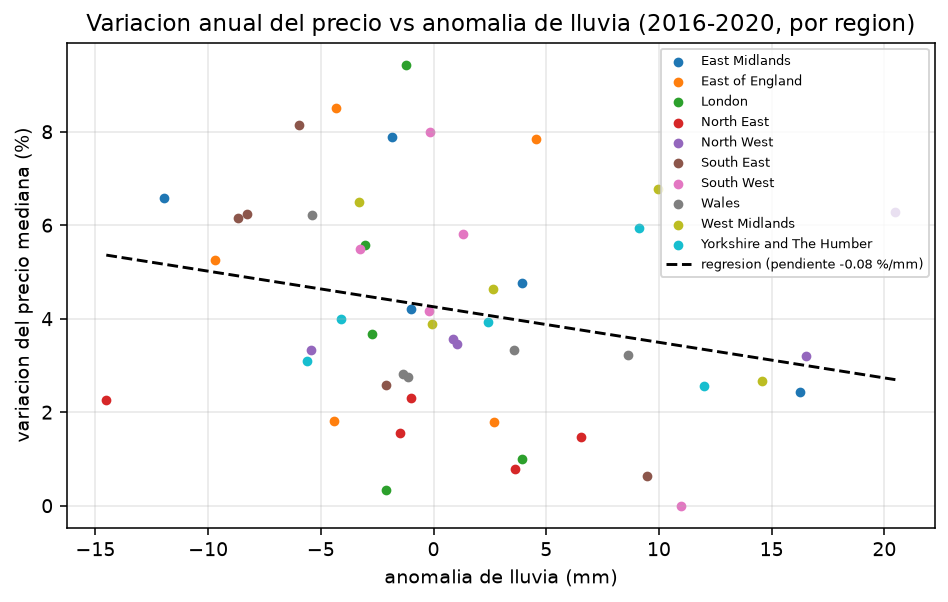

In [6]:
presentar(graficos.fig_clima_precio(maestro))

## A modo de lectura

Las correlaciones son **débiles y en su mayoría negativas** (lluvia **−0,24**;
temperatura máxima **−0,39**; mínima **−0,40**; días de helada **−0,15**; sol **+0,24**,
la única con signo positivo): cuando el año estuvo por encima de su normal —más lluvia,
más calor o más heladas—, la suba del precio tendió a ser menor.

Cuatro precisiones para que la afirmación sea honesta:

1. **Es una asociación, no una causa.** El |r| va de 0,15 a 0,40, lo que equivale a
   explicar entre el **2 % y el 16 %** de la varianza de la variación del precio
   (r² = 0,021 a 0,157). Es decir, **entre el 84 % y el 98 %** de lo que mueve el precio
   año a año queda fuera de las variables climáticas de este cruce.
2. **El signo mayoritario apunta al mismo patrón, pero es pequeño.** Cuatro de las cinco
   correlaciones son negativas —años anómalos húmedos, cálidos o helados, menos
   crecimiento—, lo que suma evidencia a favor de que no sea ruido. Pero un |r| de 0,40
   sigue siendo una relación débil: con menos del 16 % de la varianza explicada, el
   clima sirve como **contexto explicativo**, no como **variable predictiva**. El caso
   del sol es distinto en signo (más sol, más precio) y en tamaño (n = 35 de 50 pares,
   porque `sol_anom` conserva 18 nulos): una anomalía solar positiva suele coincidir con
   un verano más seco y más caluroso, de modo que su signo positivo es compatible con el
   patrón general y no lo contradice.
3. **La variable de respuesta es la variación, no el nivel.** Es una decisión
   deliberada (véase la portada): si se correlacionara el nivel del precio con el clima
   se obtendrían coeficientes mucho más altos, pero «cuanto más caro el sitio, más
   lluvia» es un artefacto de la latitud y la altitud, no un efecto del clima de cada
   año.
4. **n = 50 pares (10 regiones × 5 años con precio comparable)**. Es una muestra
   pequeña: con n = 50, un |r| de 0,40 tiene significación práctica pero su margen de
   error es amplio. Conviene leer estas magnitudes como **indicios** y no como
   estimaciones precisas del efecto climático.

**Conclusión de la hipótesis H3.** El clima **no es** el motor de la accesibilidad de
la vivienda joven: el fundamento lo da el binomio **salario joven – tasa hipotecaria –
oferta regional** que se trabaja en el libro 04. Lo que el clima aporta es un matiz:
los años climáticamente anómalos tiñen, con signo negativo y de forma débil, el
crecimiento de los precios.

## Cierre del cuaderno

Con esto queda cerrado el cruce: **años de salario (F1 + F4) · hipoteca 2022 (F2) ·
clima marginal (F3)**. El cuadro maestro completo queda en
`data/integrado/maestro_joven_uk.parquet` (60 filas × 16 columnas).

**Lo que este cuaderno deja establecido:**

1. La **anomalía climática** (diferencia respecto a la normal 1931-2020) se calcula
   por estación y se agrega a región, con unidades físicas preservadas.
2. El **Pearson clima → variación del precio** es débil y negativo (|r| de 0,24 a 0,40),
   equivalente a explicar entre el 6 % y el 16 % de la varianza anual.
3. El **clima es contexto, no motor** de la accesibilidad: la hipótesis H3 queda
   acotada en ese sentido.

Siguiente paso: el libro 06 construye la **matriz X·y** sobre este mismo cuadro maestro.

In [7]:
# Verificacion de cobertura del cruce clima x precio y del maestro resultante
print(f"anomalia regional: {anom_reg.shape[0]} region-anos "
      f"({anom_reg['region'].nunique()} regiones, ventana historica completa)")
print(f"anomalia nacional: {anom_nac['anio'].nunique()} anos "
      f"({anom_nac['anio'].min()}-{anom_nac['anio'].max()}, normal 1931-2020)")
print()
print(f"maestro final: {maestro.shape[0]} filas x {maestro.shape[1]} columnas")
print(f"ventana de cruce con las 4 fuentes: {maestro['anio'].min()}-{maestro['anio'].max()}")
print(f"pares region-ano con clima y precio ambos presentes: "
      f"{int(maestro[['lluvia_anom','precio_var_pct']].dropna().shape[0])} de {len(maestro)}")
print()
print("columnas climaticas del maestro, unidad y rango observado:")
for col, uni in [("tmax_anom", "desviacion (C)"), ("tmin_anom", "desviacion (C)"),
                 ("lluvia_anom", "mm"), ("sol_anom", "horas"),
                 ("af_anom", "dias")]:
    print(f"  {col:<12} {uni:<15} rango "
          f"{maestro[col].min():+.1f} a {maestro[col].max():+.1f}")

anomalia regional: 1027 region-anos (10 regiones, ventana historica completa)
anomalia nacional: 168 anos (1853.0-2020.0, normal 1931-2020)

maestro final: 60 filas x 16 columnas
ventana de cruce con las 4 fuentes: 2015-2020
pares region-ano con clima y precio ambos presentes: 50 de 60

columnas climaticas del maestro, unidad y rango observado:
  tmax_anom    desviacion (C)  rango -0.7 a +2.1
  tmin_anom    desviacion (C)  rango -1.2 a +1.8
  lluvia_anom  mm              rango -14.5 a +22.6
  sol_anom     horas           rango -20.5 a +72.6
  af_anom      dias            rango -43.0 a +8.7
